In [1]:
!pip -q install textblob vaderSentiment

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

In [3]:
texts = [
    "I absolutely love this phone, the camera is amazing!",
    "This is the worst service I have ever experienced.",
    "The movie was okay, nothing special.",
    "The food was GREAT!!! Will definitely come again :)",
    "I do not like the new update at all.",
    "The delivery was not bad.",
    "Battery life is terrible but the screen is gorgeous.",
    "The meeting is scheduled for 3 PM tomorrow.",
]

In [4]:
def tb_label(p): return "Positive" if p > 0.05 else "Negative" if p < -0.05 else "Neutral"
tb = [TextBlob(t).sentiment for t in texts]
for t, s in zip(texts, tb):
    print(f"{s.polarity:+.2f}  subj={s.subjectivity:.2f}  {tb_label(s.polarity):8s} | {t}")

+0.62  subj=0.75  Positive | I absolutely love this phone, the camera is amazing!
-0.10  subj=0.95  Negative | This is the worst service I have ever experienced.
+0.43  subj=0.54  Positive | The movie was okay, nothing special.
+0.50  subj=0.75  Positive | The food was GREAT!!! Will definitely come again :)
+0.14  subj=0.45  Positive | I do not like the new update at all.
+0.35  subj=0.67  Positive | The delivery was not bad.
-0.15  subj=0.95  Negative | Battery life is terrible but the screen is gorgeous.
+0.00  subj=0.00  Neutral  | The meeting is scheduled for 3 PM tomorrow.


In [5]:
def vd_label(c): return "Positive" if c >= 0.05 else "Negative" if c <= -0.05 else "Neutral"
vd = [vader.polarity_scores(t) for t in texts]
for t, s in zip(texts, vd):
    print(f"{s['compound']:+.3f}  neg={s['neg']:.2f} neu={s['neu']:.2f} pos={s['pos']:.2f}  {vd_label(s['compound']):8s} | {t}")

+0.862  neg=0.00 neu=0.45 pos=0.55  Positive | I absolutely love this phone, the camera is amazing!
-0.625  neg=0.34 neu=0.66 pos=0.00  Negative | This is the worst service I have ever experienced.
-0.092  neg=0.28 neu=0.49 pos=0.23  Negative | The movie was okay, nothing special.
+0.908  neg=0.00 neu=0.34 pos=0.66  Positive | The food was GREAT!!! Will definitely come again :)
-0.276  neg=0.21 neu=0.79 pos=0.00  Negative | I do not like the new update at all.
+0.431  neg=0.00 neu=0.58 pos=0.42  Positive | The delivery was not bad.
+0.665  neg=0.14 neu=0.48 pos=0.38  Positive | Battery life is terrible but the screen is gorgeous.
+0.000  neg=0.00 neu=1.00 pos=0.00  Neutral  | The meeting is scheduled for 3 PM tomorrow.


,text,TextBlob_polarity,TextBlob_label,VADER_compound,VADER_label,agree
0,"I absolutely love this phone, the camera is amazing!",0.625000,Positive,0.8620,Positive,True
1,This is the worst service I have ever experienced.,-0.100000,Negative,-0.6249,Negative,True
2,"The movie was okay, nothing special.",0.428571,Positive,-0.0920,Negative,False
3,The food was GREAT!!! Will definitely come again :),0.500000,Positive,0.9083,Positive,True
4,I do not like the new update at all.,0.136364,Positive,-0.2755,Negative,False
5,The delivery was not bad.,0.350000,Positive,0.4310,Positive,True
6,Battery life is terrible but the screen is gorgeous.,-0.150000,Negative,0.6652,Positive,False
7,The meeting is scheduled for 3 PM tomorrow.,0.000000,Neutral,0.0000,Neutral,True


Agreement: 0.62


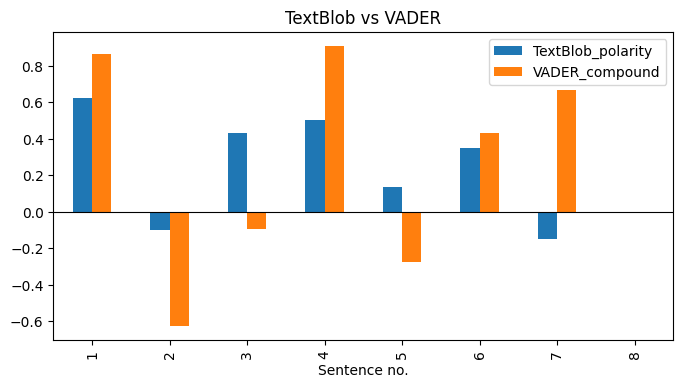

In [6]:
df = pd.DataFrame({
    "text": texts,
    "TextBlob_polarity": [s.polarity for s in tb],
    "TextBlob_label": [tb_label(s.polarity) for s in tb],
    "VADER_compound": [s["compound"] for s in vd],
    "VADER_label": [vd_label(s["compound"]) for s in vd],
})
df["agree"] = df.TextBlob_label == df.VADER_label
pd.set_option("display.max_colwidth", 60)
display(df)
print("Agreement:", df.agree.mean().round(2))

df.set_index(df.index + 1)[["TextBlob_polarity", "VADER_compound"]].plot(kind="bar", figsize=(8, 4))
plt.axhline(0, color="k", lw=0.8); plt.xlabel("Sentence no."); plt.title("TextBlob vs VADER"); plt.show()